In [1]:
# Imports and project Configuration

from pathlib import Path
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mysql.connector
from dotenv import load_dotenv

PROJECT_ROOT = Path(
    r"C:\PORTFOLIO\NFHS-5-Healthcare-Analytics-District-Intelligence"
)

REPORT_DIR = PROJECT_ROOT / "Reports" / "05_business_analysis"
MAPPING_FILE = (
    PROJECT_ROOT
    / "Reports"
    / "04_mysql_load_and_validation"
    / "column_mapping.csv"
)

REPORT_DIR.mkdir(parents=True, exist_ok=True)
load_dotenv(PROJECT_ROOT / ".env")

DATABASE_NAME = os.getenv("MYSQL_DATABASE", "nfhs5_healthcare")
TABLE_NAME = "nfhs_district_data"

MIN_DISTRICTS_FOR_COMPARISON = 500

print(f"Project: {PROJECT_ROOT}")
print(f"Reports: {REPORT_DIR}")

Project: C:\PORTFOLIO\NFHS-5-Healthcare-Analytics-District-Intelligence
Reports: C:\PORTFOLIO\NFHS-5-Healthcare-Analytics-District-Intelligence\Reports\05_business_analysis


In [2]:
# Connect to MySQL and load the data

# 1. Validate the column mapping file
if not MAPPING_FILE.exists():
    raise FileNotFoundError(
        f"Column mapping not found: {MAPPING_FILE}. "
        "Run Notebook 4 successfully first."
    )

mapping = pd.read_csv(MAPPING_FILE)

required_mapping_columns = {"original_column", "mysql_column"}

if not required_mapping_columns.issubset(mapping.columns):
    raise ValueError(
        "Column mapping must contain 'original_column' "
        "and 'mysql_column'."
    )

if mapping["mysql_column"].duplicated().any():
    raise ValueError(
        "Duplicate MySQL column names found in the column mapping."
    )

mysql_to_original = dict(
    zip(mapping["mysql_column"], mapping["original_column"])
)


# 2. Connect to MySQL and retrieve the district data
connection = None
cursor = None

try:
    connection = mysql.connector.connect(
        host=os.getenv("MYSQL_HOST", "localhost"),
        port=int(os.getenv("MYSQL_PORT", "3306")),
        user=os.getenv("MYSQL_USER"),
        password=os.getenv("MYSQL_PASSWORD"),
        database=DATABASE_NAME,
    )

    cursor = connection.cursor()
    cursor.execute(f"SELECT * FROM `{TABLE_NAME}`")

    rows = cursor.fetchall()
    column_names = [column[0] for column in cursor.description]

    df = pd.DataFrame(rows, columns=column_names)

finally:
    if cursor is not None:
        cursor.close()

    if connection is not None and connection.is_connected():
        connection.close()


# 3. Restore the original dataset column names
df = df.rename(columns=mysql_to_original)

required_columns = {"district_names", "state_ut"}

if not required_columns.issubset(df.columns):
    missing_columns = required_columns - set(df.columns)

    raise ValueError(
        f"Missing required columns after applying the mapping: "
        f"{missing_columns}"
    )

if df.empty:
    raise ValueError(
        f"The MySQL table '{TABLE_NAME}' contains no district records."
    )


# 4. Identify and convert numeric indicator columns
indicator_columns = []

for column in df.columns:
    if column in required_columns:
        continue

    numeric_values = pd.to_numeric(df[column], errors="coerce")

    # Include columns containing at least one valid numeric value.
    if numeric_values.notna().any():
        df[column] = numeric_values
        indicator_columns.append(column)

if not indicator_columns:
    print("Available columns:", df.columns.tolist())
    print("Column data types:")
    print(df.dtypes.to_string())

    raise ValueError(
        "No numeric indicators were identified. "
        "Review the column mapping and MySQL data types."
    )


# 5. Validate district and state identifiers
for column in required_columns:
    df[column] = df[column].astype("string").str.strip()

missing_identifiers = (
    df["district_names"].isna()
    | df["district_names"].eq("")
    | df["state_ut"].isna()
    | df["state_ut"].eq("")
)

if missing_identifiers.any():
    raise ValueError(
        f"{int(missing_identifiers.sum())} records have missing "
        "or blank district/state identifiers."
    )


# 6. Display the loading summary
print(f"District records loaded: {len(df)}")
print(f"Numeric indicators available: {len(indicator_columns)}")
print(f"States/UTs represented: {df['state_ut'].nunique()}")
print(f"Missing district/state identifiers: {int(missing_identifiers.sum())}")

District records loaded: 707
Numeric indicators available: 107
States/UTs represented: 36
Missing district/state identifiers: 0


In [3]:
# Create Indicator catalogue

indicator_catalog = pd.DataFrame({
    "indicator": indicator_columns,
    "districts_with_data": [
        int(df[column].notna().sum()) for column in indicator_columns
    ],
    "missing_percentage": [
        round(df[column].isna().mean() * 100, 2)
        for column in indicator_columns
    ],
    "district_average": [
        df[column].mean() for column in indicator_columns
    ],
})

indicator_catalog["eligible_for_comparison"] = (
    (indicator_catalog["districts_with_data"]
     >= MIN_DISTRICTS_FOR_COMPARISON)
    & (indicator_catalog["missing_percentage"] <= 20)
)

indicator_catalog = indicator_catalog.sort_values(
    ["eligible_for_comparison", "missing_percentage"],
    ascending=[False, True],
)

indicator_catalog.to_csv(
    REPORT_DIR / "indicator_catalog.csv",
    index=False,
)

display(indicator_catalog.head(15))

print(
    "Indicators meeting the initial coverage threshold: "
    f"{indicator_catalog['eligible_for_comparison'].sum()}"
)

,indicator,districts_with_data,missing_percentage,district_average,eligible_for_comparison
0,number_of_households_surveyed,707,0.0,900.502122,True
1,number_of_women_age_15_49_years_interviewed,707,0.0,1024.019802,True
2,number_of_men_age_15_54_years_interviewed,707,0.0,144.002829,True
3,female_population_age_6_years_and_above_who_ev...,707,0.0,71.507822,True
4,population_below_age_15_years,707,0.0,26.356874,True
5,sex_ratio_of_the_total_population_females_per_...,707,0.0,1020.696139,True
7,children_under_age_5_years_whose_birth_was_reg...,707,0.0,91.064795,True
9,population_living_in_households_with_electricity,707,0.0,96.996025,True
10,population_living_in_households_with_an_improv...,707,0.0,93.726054,True
11,population_living_in_households_that_use_an_im...,707,0.0,71.917496,True


Indicators meeting the initial coverage threshold: 85


In [4]:
# Create Indicator catalogue

indicator_catalog = pd.DataFrame({
    "indicator": indicator_columns,
    "districts_with_data": [
        int(df[column].notna().sum()) for column in indicator_columns
    ],
    "missing_percentage": [
        round(df[column].isna().mean() * 100, 2)
        for column in indicator_columns
    ],
    "district_average": [
        df[column].mean() for column in indicator_columns
    ],
})

indicator_catalog["eligible_for_comparison"] = (
    (indicator_catalog["districts_with_data"]
     >= MIN_DISTRICTS_FOR_COMPARISON)
    & (indicator_catalog["missing_percentage"] <= 20)
)

indicator_catalog = indicator_catalog.sort_values(
    ["eligible_for_comparison", "missing_percentage"],
    ascending=[False, True],
)

indicator_catalog.to_csv(
    REPORT_DIR / "indicator_catalog.csv",
    index=False,
)

display(indicator_catalog.head(15))

print(
    "Indicators meeting the initial coverage threshold: "
    f"{indicator_catalog['eligible_for_comparison'].sum()}"
)

,indicator,districts_with_data,missing_percentage,district_average,eligible_for_comparison
0,number_of_households_surveyed,707,0.0,900.502122,True
1,number_of_women_age_15_49_years_interviewed,707,0.0,1024.019802,True
2,number_of_men_age_15_54_years_interviewed,707,0.0,144.002829,True
3,female_population_age_6_years_and_above_who_ev...,707,0.0,71.507822,True
4,population_below_age_15_years,707,0.0,26.356874,True
5,sex_ratio_of_the_total_population_females_per_...,707,0.0,1020.696139,True
7,children_under_age_5_years_whose_birth_was_reg...,707,0.0,91.064795,True
9,population_living_in_households_with_electricity,707,0.0,96.996025,True
10,population_living_in_households_with_an_improv...,707,0.0,93.726054,True
11,population_living_in_households_that_use_an_im...,707,0.0,71.917496,True


Indicators meeting the initial coverage threshold: 85


In [5]:
# Select healthcare KPIs

kpi_candidates = [
    ("Child nutrition", "Stunting",
     "children_under_5_years_who_are_stunted"),
    ("Child nutrition", "Wasting",
     "children_under_5_years_who_are_wasted"),
    ("Child nutrition", "Underweight",
     "children_under_5_years_who_are_underweight"),
    ("Maternal healthcare", "Antenatal care",
     "mothers_who_had_at_least_4_antenatal_care_visi"),
    ("Maternal healthcare", "Institutional births",
     "institutional_births_in_the_5_years_before_the_survey"),
    ("Immunisation", "Full vaccination",
     "children_age_12_23_months_fully_vaccinated"),
]

selected_kpis = []
selection_results = []
used_indicators = set()

for dimension, kpi_name, phrase in kpi_candidates:
    matches = [
        column for column in indicator_columns
        if phrase in column.lower()
        and column not in used_indicators
    ]

    eligible_matches = [
        column for column in matches
        if bool(
            indicator_catalog.set_index("indicator")
            .loc[column, "eligible_for_comparison"]
        )
    ]

    if eligible_matches:
        selected = max(
            eligible_matches,
            key=lambda column: df[column].notna().sum(),
        )
        selected_kpis.append({
            "dimension": dimension,
            "kpi_name": kpi_name,
            "indicator": selected,
        })
        used_indicators.add(selected)
        status = "Selected"
    else:
        selected = matches[0] if matches else None
        status = (
            "Excluded: insufficient coverage"
            if selected else "No matching indicator found"
        )

    selection_results.append({
        "dimension": dimension,
        "kpi_name": kpi_name,
        "indicator": selected,
        "status": status,
    })

selection_log = pd.DataFrame(selection_results)
selected_kpis_df = pd.DataFrame(selected_kpis)

selection_log.to_csv(
    REPORT_DIR / "kpi_selection_log.csv",
    index=False,
)
selected_kpis_df.to_csv(
    REPORT_DIR / "selected_kpis.csv",
    index=False,
)

display(selection_log)
display(selected_kpis_df)

if selected_kpis_df.empty:
    raise ValueError(
        "No candidate KPIs passed the coverage screen. "
        "Review indicator_catalog.csv and kpi_selection_log.csv."
    )

,dimension,kpi_name,indicator,status
0,Child nutrition,Stunting,children_under_5_years_who_are_stunted_height_...,Selected
1,Child nutrition,Wasting,children_under_5_years_who_are_wasted_weight_f...,Selected
2,Child nutrition,Underweight,children_under_5_years_who_are_underweight_wei...,Selected
3,Maternal healthcare,Antenatal care,mothers_who_had_at_least_4_antenatal_care_visi...,Selected
4,Maternal healthcare,Institutional births,institutional_births_in_the_5_years_before_the...,Selected
5,Immunisation,Full vaccination,children_age_12_23_months_fully_vaccinated_bas...,Excluded: insufficient coverage


,dimension,kpi_name,indicator
0,Child nutrition,Stunting,children_under_5_years_who_are_stunted_height_...
1,Child nutrition,Wasting,children_under_5_years_who_are_wasted_weight_f...
2,Child nutrition,Underweight,children_under_5_years_who_are_underweight_wei...
3,Maternal healthcare,Antenatal care,mothers_who_had_at_least_4_antenatal_care_visi...
4,Maternal healthcare,Institutional births,institutional_births_in_the_5_years_before_the...


In [6]:

# Descriptive statistics for selected healthcare KPIs

descriptive_rows = []

for kpi in selected_kpis:
    indicator = kpi["indicator"]
    values = pd.to_numeric(df[indicator], errors="coerce").dropna()

    descriptive_rows.append({
        "dimension": kpi["dimension"],
        "kpi_name": kpi["kpi_name"],
        "indicator": indicator,
        "districts_with_data": len(values),
        "missing_percentage": round(df[indicator].isna().mean() * 100, 2),
        "mean": values.mean(),
        "median": values.median(),
        "standard_deviation": values.std(),
        "minimum": values.min(),
        "maximum": values.max(),
    })

kpi_descriptive_statistics = pd.DataFrame(descriptive_rows)

kpi_descriptive_statistics.to_csv(
    REPORT_DIR / "kpi_descriptive_statistics.csv",
    index=False,
)

display(kpi_descriptive_statistics)

,dimension,kpi_name,indicator,districts_with_data,missing_percentage,mean,median,standard_deviation,minimum,maximum
0,Child nutrition,Stunting,children_under_5_years_who_are_stunted_height_...,706,0.14,33.522309,32.835,8.446826,13.16,60.61
1,Child nutrition,Wasting,children_under_5_years_who_are_wasted_weight_f...,706,0.14,18.542351,18.110,6.496890,4.46,48.03
2,Child nutrition,Underweight,children_under_5_years_who_are_underweight_wei...,706,0.14,29.518286,29.340,9.714873,7.17,62.38
3,Maternal healthcare,Antenatal care,mothers_who_had_at_least_4_antenatal_care_visi...,706,0.14,60.496813,62.535,20.279586,4.36,98.65
4,Maternal healthcare,Institutional births,institutional_births_in_the_5_years_before_the...,707,0.00,88.670382,92.200,12.001523,21.40,100.00


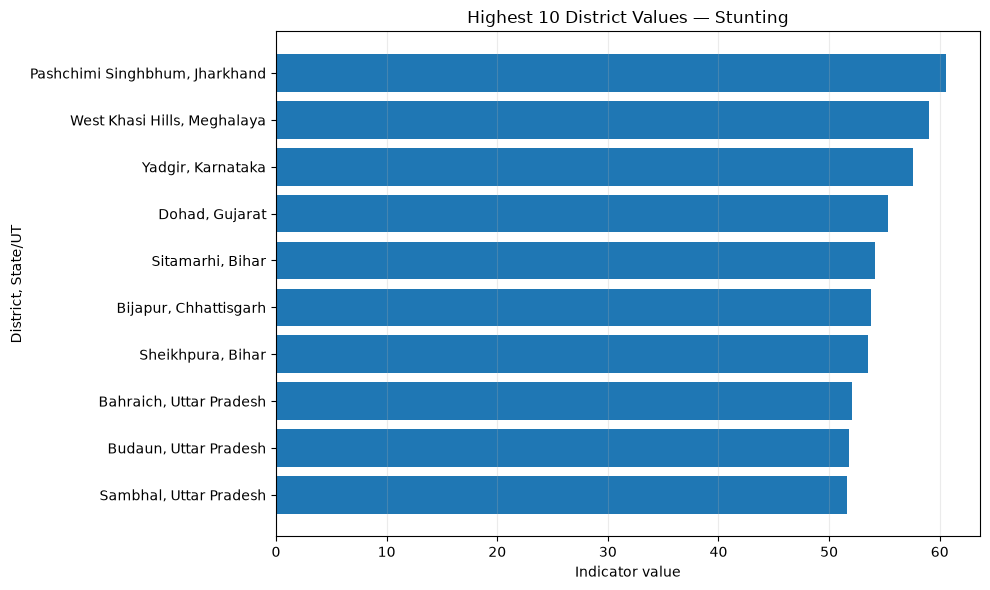

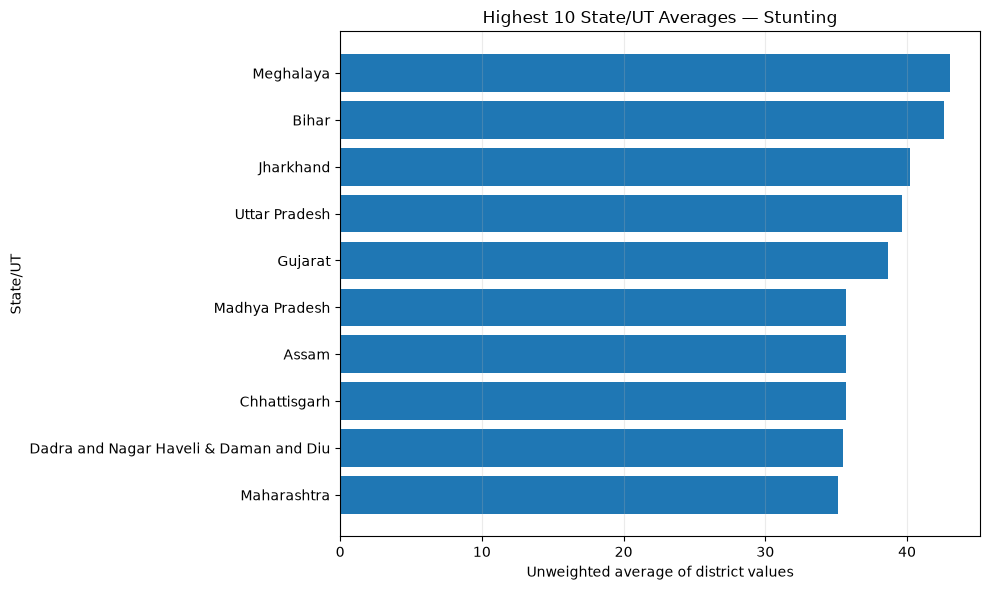

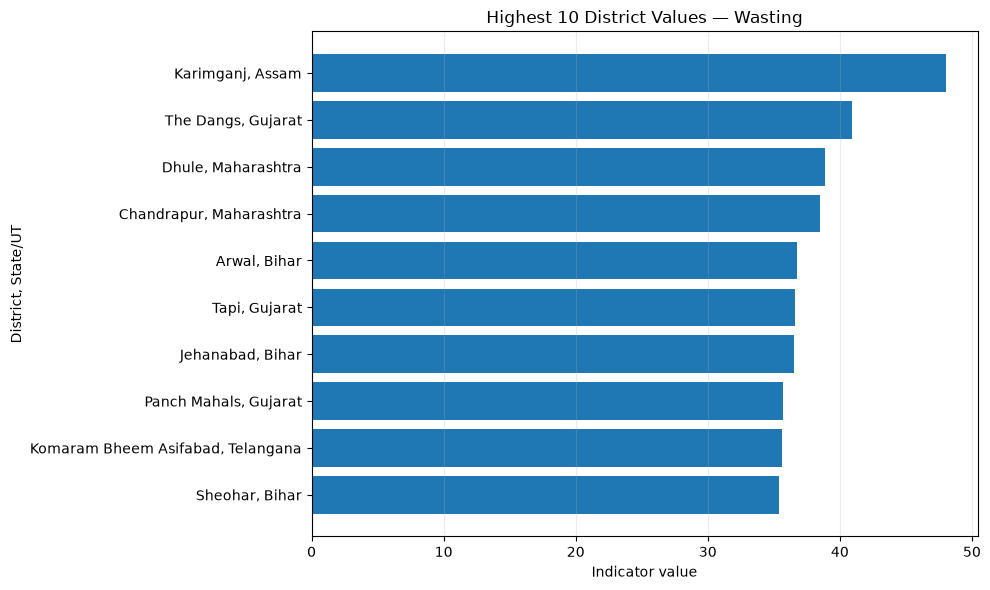

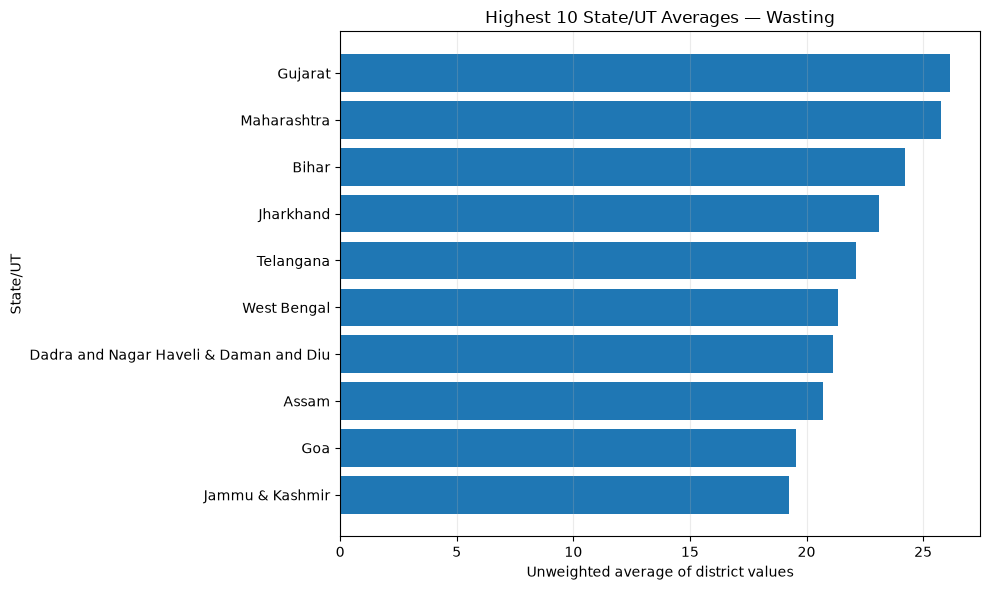

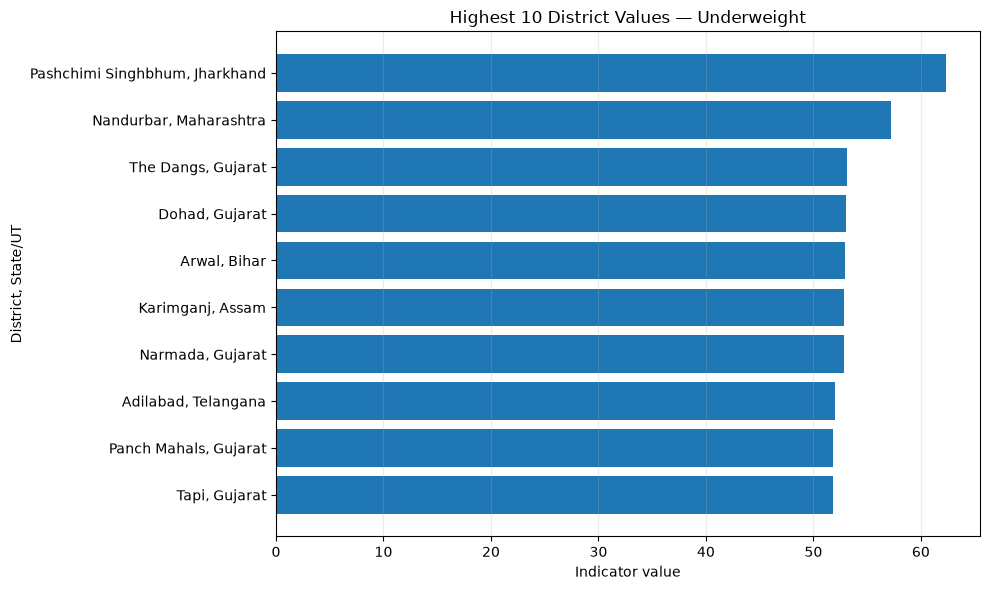

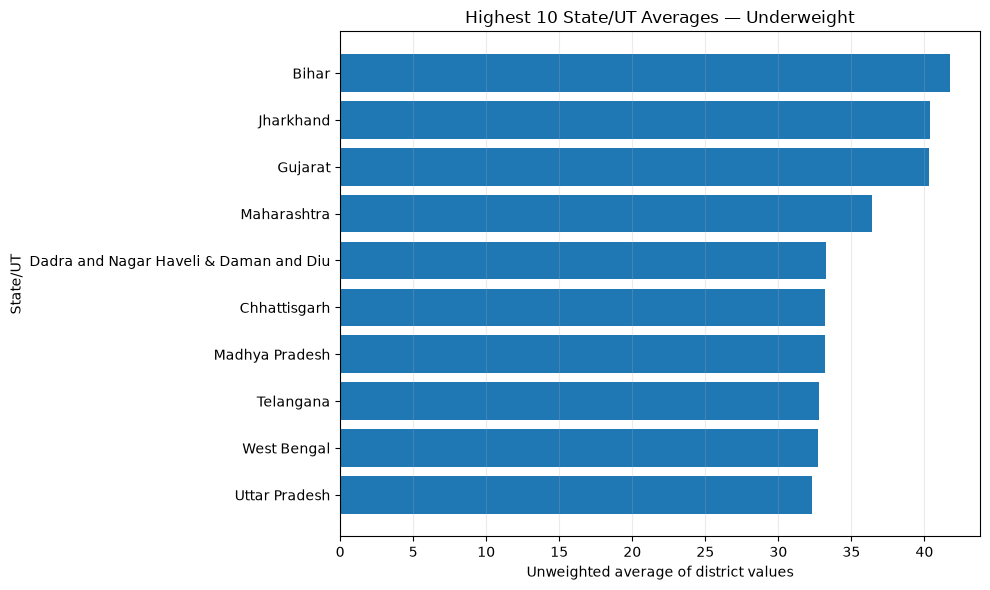

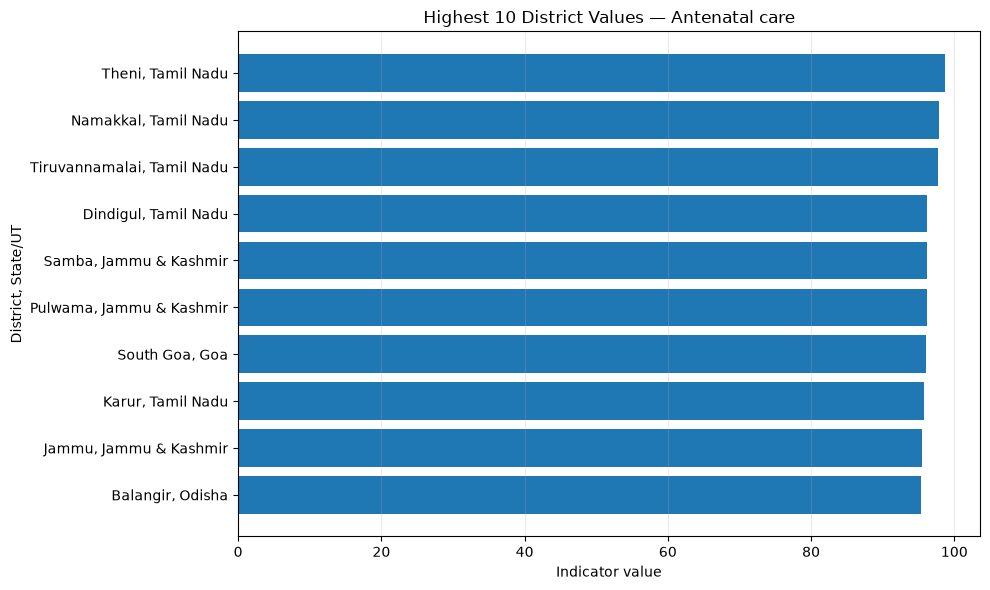

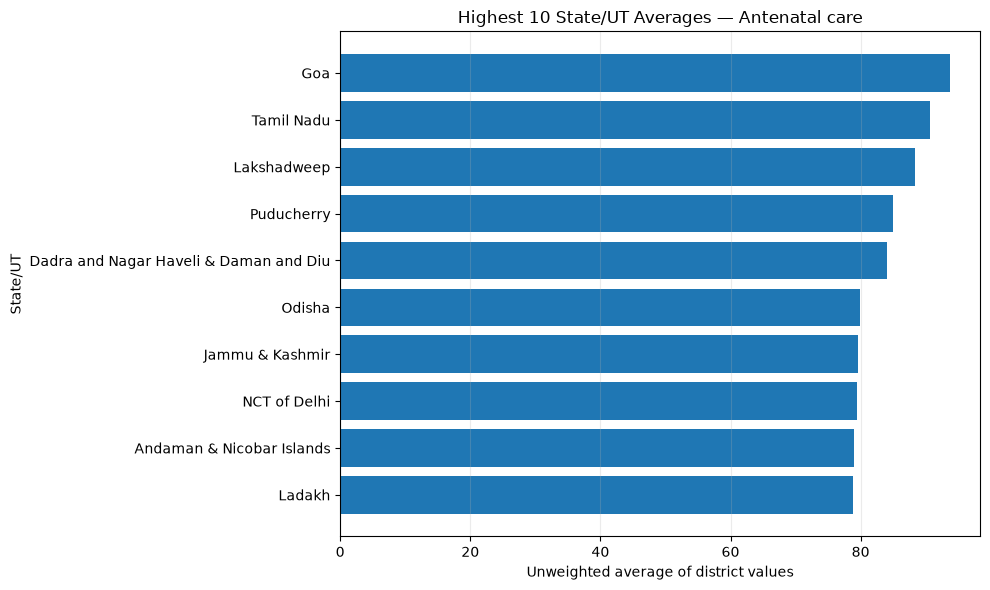

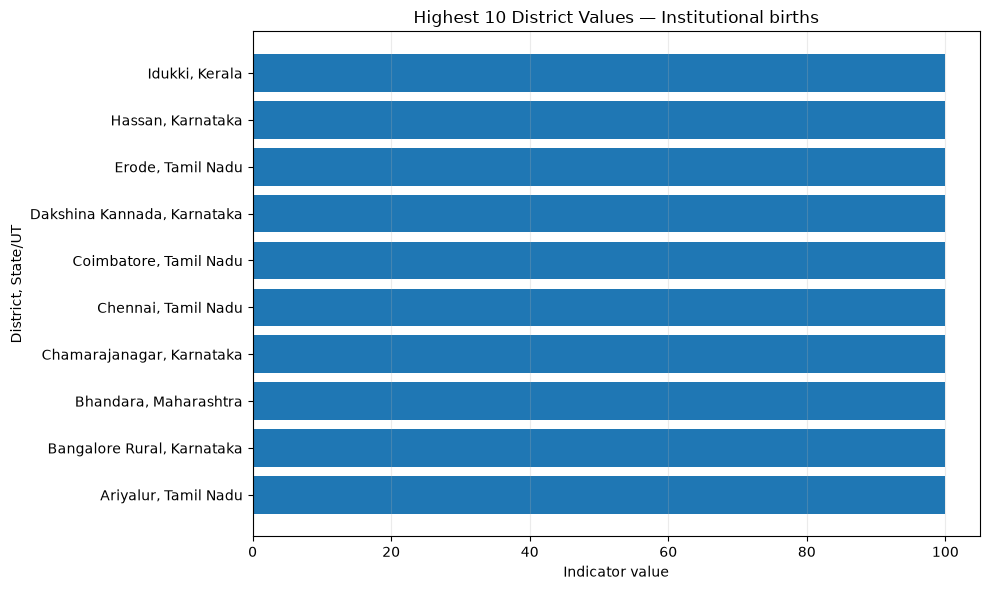

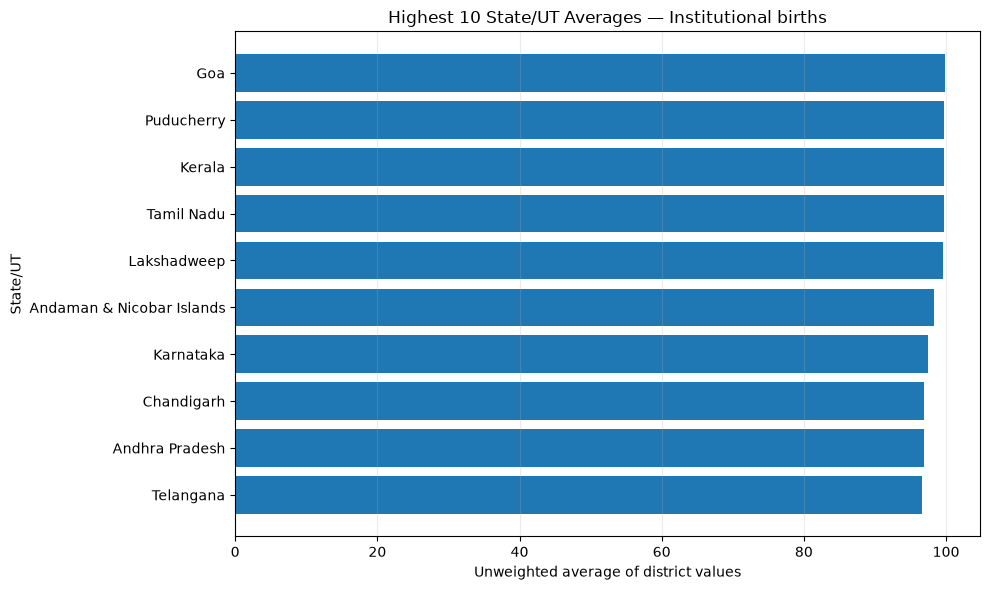

,dimension,kpi_name,indicator,districts_with_data,missing_percentage,unweighted_district_average,district_median,highest_district,highest_district_state,highest_value,lowest_district,lowest_district_state,lowest_value
0,Child nutrition,Stunting,children_under_5_years_who_are_stunted_height_...,706,0.14,33.522309,32.835,Pashchimi Singhbhum,Jharkhand,60.61,Jagatsinghapur,Odisha,13.16
1,Child nutrition,Wasting,children_under_5_years_who_are_wasted_weight_f...,706,0.14,18.542351,18.110,Karimganj,Assam,48.03,North District,Sikkim,4.46
2,Child nutrition,Underweight,children_under_5_years_who_are_underweight_wei...,706,0.14,29.518286,29.340,Pashchimi Singhbhum,Jharkhand,62.38,South District,Sikkim,7.17
3,Maternal healthcare,Antenatal care,mothers_who_had_at_least_4_antenatal_care_visi...,706,0.14,60.496813,62.535,Theni,Tamil Nadu,98.65,Tuensang,Nagaland,4.36
4,Maternal healthcare,Institutional births,institutional_births_in_the_5_years_before_the...,707,0.00,88.670382,92.200,Ariyalur,Tamil Nadu,100.00,Mon,Nagaland,21.40


KPIs analysed: 5
Analysis reports saved to: C:\PORTFOLIO\NFHS-5-Healthcare-Analytics-District-Intelligence\Reports\05_business_analysis


In [7]:

# KPI analysis, district rankings, and charts

def safe_filename(value):
    return re.sub(r"[^a-z0-9]+", "_", value.lower()).strip("_")


summary_rows = []

for kpi in selected_kpis:
    indicator = kpi["indicator"]
    kpi_name = kpi["kpi_name"]
    filename = safe_filename(kpi_name)

    # Prepare available district-level values
    values = df[
        ["district_names", "state_ut", indicator]
    ].dropna(subset=[indicator]).copy()

    if values.empty:
        print(f"Skipping {kpi_name}: no available district values.")
        continue

    # State/UT comparison using available district values
    state_comparison = (
        values.groupby("state_ut")[indicator]
        .agg(
            unweighted_district_average="mean",
            district_median="median",
            districts_with_data="count",
        )
        .reset_index()
        .sort_values(
            "unweighted_district_average",
            ascending=False,
        )
    )

    # Identify the highest and lowest 10 districts
    highest_10 = values.nlargest(10, indicator)
    lowest_10 = values.nsmallest(10, indicator)

    # Export analytical tables
    state_comparison.to_csv(
        REPORT_DIR / f"{filename}_state_comparison.csv",
        index=False,
    )

    highest_10.to_csv(
        REPORT_DIR / f"{filename}_highest_10_districts.csv",
        index=False,
    )

    lowest_10.to_csv(
        REPORT_DIR / f"{filename}_lowest_10_districts.csv",
        index=False,
    )

    # Add KPI results to the consolidated summary
    summary_rows.append({
        "dimension": kpi["dimension"],
        "kpi_name": kpi_name,
        "indicator": indicator,
        "districts_with_data": len(values),
        "missing_percentage": round(
            df[indicator].isna().mean() * 100, 2
        ),
        "unweighted_district_average": values[indicator].mean(),
        "district_median": values[indicator].median(),
        "highest_district": highest_10.iloc[0]["district_names"],
        "highest_district_state": highest_10.iloc[0]["state_ut"],
        "highest_value": highest_10.iloc[0][indicator],
        "lowest_district": lowest_10.iloc[0]["district_names"],
        "lowest_district_state": lowest_10.iloc[0]["state_ut"],
        "lowest_value": lowest_10.iloc[0][indicator],
    })

    # Chart 1: Highest 10 districts
    chart_data = values.nlargest(10, indicator).sort_values(indicator)

    labels = (
        chart_data["district_names"].astype(str)
        + ", "
        + chart_data["state_ut"].astype(str)
    )

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(labels, chart_data[indicator])
    ax.set_xlabel("Indicator value")
    ax.set_ylabel("District, State/UT")
    ax.set_title(f"Highest 10 District Values — {kpi_name}")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()

    fig.savefig(
        REPORT_DIR / f"{filename}_top_10_districts.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    # Chart 2: Highest 10 state/UT unweighted district averages
    top_states = (
        state_comparison.nlargest(
            10, "unweighted_district_average"
        )
        .sort_values("unweighted_district_average")
    )

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(
        top_states["state_ut"],
        top_states["unweighted_district_average"],
    )
    ax.set_xlabel("Unweighted average of district values")
    ax.set_ylabel("State/UT")
    ax.set_title(f"Highest 10 State/UT Averages — {kpi_name}")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()

    fig.savefig(
        REPORT_DIR / f"{filename}_top_10_states_ut.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


# Save and display the consolidated KPI summary
if not summary_rows:
    raise ValueError(
        "No KPI results were generated. Review the KPI selection cell."
    )

kpi_summary = pd.DataFrame(summary_rows)

kpi_summary.to_csv(
    REPORT_DIR / "kpi_summary.csv",
    index=False,
)

display(kpi_summary)

print(f"KPIs analysed: {len(kpi_summary)}")
print(f"Analysis reports saved to: {REPORT_DIR}")

In [8]:
# Business insights and recommendations

recommendations = {
    "Stunting": (
        "Prioritise a review of districts with high stunting prevalence. "
        "Assess child nutrition services and relevant local factors."
    ),
    "Wasting": (
        "Review districts with high wasting prevalence and assess "
        "nutrition screening, referral, and treatment services."
    ),
    "Underweight": (
        "Investigate districts with high underweight prevalence and "
        "coordinate a review of child nutrition interventions."
    ),
    "Antenatal care": (
        "Investigate districts with low coverage of four or more "
        "antenatal visits and assess barriers to regular care."
    ),
    "Institutional births": (
        "Investigate districts with low institutional-birth coverage "
        "and assess access, referral, transport, and service barriers."
    ),
    "Full vaccination": (
        "Investigate districts with low full-vaccination coverage "
        "and review immunisation access and follow-up."
    ),
}

insight_rows = []

for _, row in kpi_summary.iterrows():
    kpi_name = row["kpi_name"]

    if kpi_name in {"Stunting", "Wasting", "Underweight"}:
        priority_district = row["highest_district"]
        priority_state = row["highest_district_state"]
        priority_value = row["highest_value"]
        priority_basis = "Highest observed value"
    else:
        priority_district = row["lowest_district"]
        priority_state = row["lowest_district_state"]
        priority_value = row["lowest_value"]
        priority_basis = "Lowest observed value"

    insight_rows.append({
        "dimension": row["dimension"],
        "kpi_name": kpi_name,
        "districts_with_data": row["districts_with_data"],
        "district_average": round(
            row["unweighted_district_average"], 2
        ),
        "district_median": round(row["district_median"], 2),
        "priority_district": priority_district,
        "priority_state_ut": priority_state,
        "priority_value": priority_value,
        "priority_basis": priority_basis,
        "recommended_action": recommendations.get(
            kpi_name,
            "Review the official indicator definition and investigate "
            "districts with concerning values."
        ),
        "evidence_limitation": (
            "Descriptive district-level comparison; not population-weighted "
            "and does not establish causation."
        ),
    })

business_insights = pd.DataFrame(insight_rows)

insights_file = REPORT_DIR / "business_insights_and_recommendations.csv"
business_insights.to_csv(insights_file, index=False)

display(business_insights)

print(f"Business insights created: {len(business_insights)}")
print(f"Saved to: {insights_file}")

,dimension,kpi_name,districts_with_data,district_average,district_median,priority_district,priority_state_ut,priority_value,priority_basis,recommended_action,evidence_limitation
0,Child nutrition,Stunting,706,33.52,32.84,Pashchimi Singhbhum,Jharkhand,60.61,Highest observed value,Prioritise a review of districts with high stu...,Descriptive district-level comparison; not pop...
1,Child nutrition,Wasting,706,18.54,18.11,Karimganj,Assam,48.03,Highest observed value,Review districts with high wasting prevalence ...,Descriptive district-level comparison; not pop...
2,Child nutrition,Underweight,706,29.52,29.34,Pashchimi Singhbhum,Jharkhand,62.38,Highest observed value,Investigate districts with high underweight pr...,Descriptive district-level comparison; not pop...
3,Maternal healthcare,Antenatal care,706,60.50,62.53,Tuensang,Nagaland,4.36,Lowest observed value,Investigate districts with low coverage of fou...,Descriptive district-level comparison; not pop...
4,Maternal healthcare,Institutional births,707,88.67,92.20,Mon,Nagaland,21.40,Lowest observed value,Investigate districts with low institutional-b...,Descriptive district-level comparison; not pop...


Business insights created: 5
Saved to: C:\PORTFOLIO\NFHS-5-Healthcare-Analytics-District-Intelligence\Reports\05_business_analysis\business_insights_and_recommendations.csv
